# 2nd Assignemnt - Drilling Operations

## Data analysis introduction

The following analysis regards the drilling operations

## Importing data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
import numpy as np

In [2]:
# ---- PARAMETERS ----

D = 5.5  #(mm)
Vc = 150    #(m/min)
N = Vc/(np.pi * D) * 1000

In [3]:
# ---- FILES UPLOAD ----

fileSession5A1A = "Analyse Usinage/Session5A1A.csv" # NON-cutting
fileSession5A1B = "Analyse Usinage/Session5A1B.csv" # cutting

df5A1A = pd.read_csv(fileSession5A1A, skiprows=9)
df5A1A = df5A1A.iloc[:, :-1]
df5A1A = df5A1A.apply(pd.to_numeric, errors='coerce')
df5A1A = df5A1A.dropna()

df5A1B = pd.read_csv(fileSession5A1B, skiprows=9)
df5A1B = df5A1B.iloc[:, :-1]
df5A1B = df5A1B.apply(pd.to_numeric, errors='coerce')
df5A1B = df5A1B.dropna()

# Naming columns
cols = ['time', 'prog_pos_x', 'meas_pos_x', 'power', 'prog_pos_y', 'meas_pos_y','prog_pos_z', 'meas_pos_z']
for df in [df5A1A, df5A1B]:
    df.columns = cols

## Cutting power analysis

mi interessa solo la potenza di tglio per analizzare le diverse operazioni, perché la potenza a vuoto è uguale per tutti, cioè non contraddistingue l'operazione!

In [4]:
# ---- Cutting Power (of the entire process) ----

# Calculate the cutting power at the SAME instant time, otherwise insert a Nan in the result
df150 = (df5A1B.set_index('time')['power'] - df5A1A.set_index('time')['power'])

df150 = df150.reset_index(name='power')

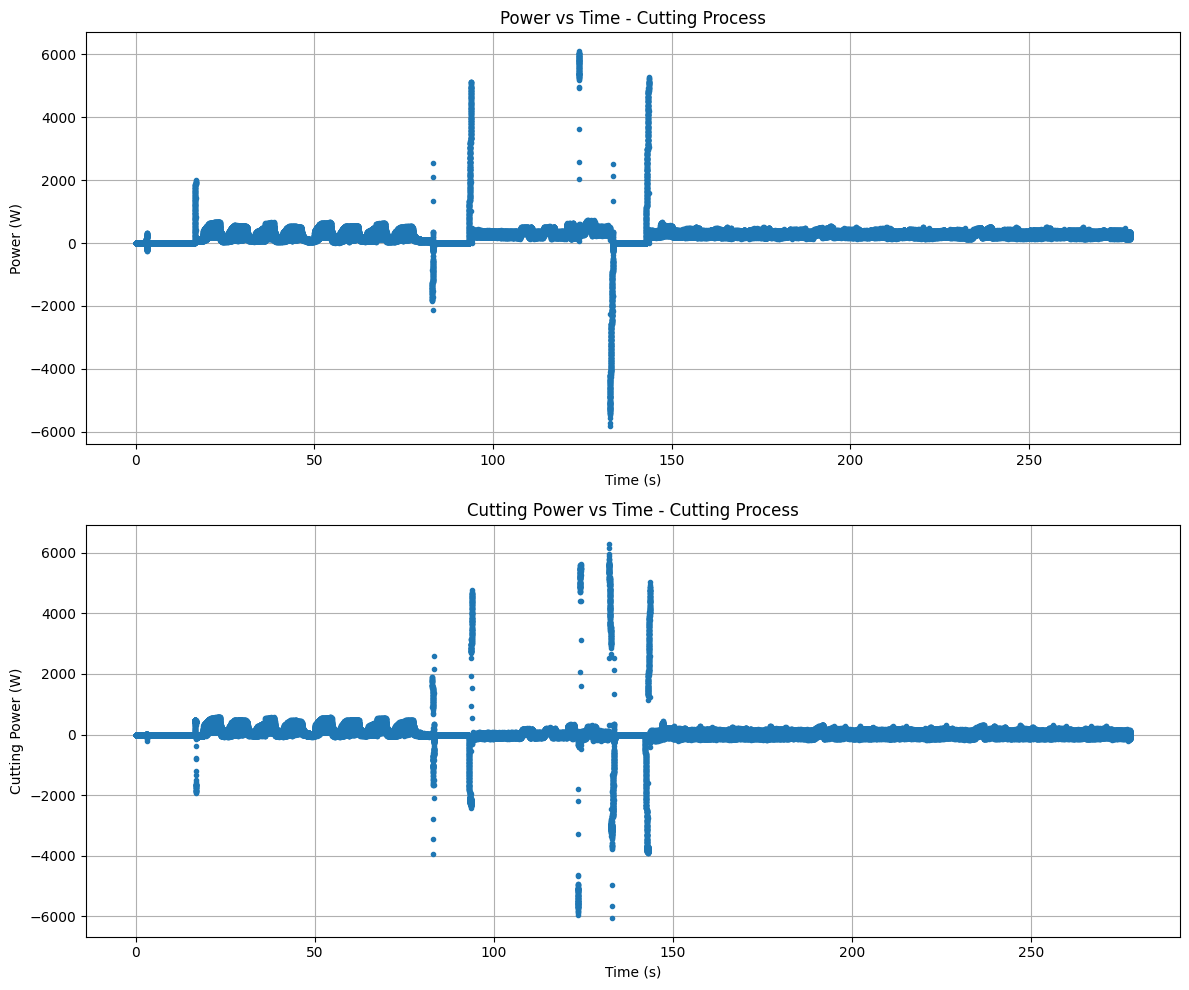

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].plot(df5A1B['time'], df5A1B['power'], marker='.', linestyle='none')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Power (W)')
axes[0].set_title('Power vs Time - Cutting Process')
axes[0].grid(True)

axes[1].plot(df150['time'], df150['power'], marker='.', linestyle='none')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Cutting Power (W)')
axes[1].set_title('Cutting Power vs Time - Cutting Process')
axes[1].grid(True)

plt.tight_layout()
plt.show()